# 01 · Receita, geografia e impacto do atraso (perguntas 1 a 3)

**Pré-requisito:** `python -m src.executar_limpeza && python -m src.executar_modelo`.

**Convenções:** faturamento = `preco` dos itens (sem frete) · apenas pedidos válidos (sem `canceled`/`unavailable`) · janela **jan/2017–ago/2018**, a única com volume relevante.

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import visualizacao as vis
from src.visualizacao import AZUL, CINZA, VERMELHO

vis.configurar()
m = vis.carregar_modelo()
fp, fi, dc, dp, dv = m["fato_pedidos"], m["fato_itens"], m["dim_cliente"], m["dim_produto"], m["dim_vendedor"]

## Pergunta 1 · Como evoluem faturamento, pedidos e ticket médio?

In [2]:
# Pedidos válidos, com ao menos 1 item, dentro da janela de análise
pv = vis.no_periodo(fp[fp["pedido_valido"] & (fp["receita"] > 0)]).copy()
pv["mes"] = pv["data_compra"].dt.to_period("M").dt.to_timestamp()

mensal = pv.groupby("mes").agg(faturamento=("receita", "sum"), pedidos=("id_pedido", "count"))
mensal["ticket_medio"] = mensal["faturamento"] / mensal["pedidos"]   # ticket = receita / nº de pedidos
mensal["var_mom"] = mensal["faturamento"].pct_change()

print(f"Faturamento no período: R$ {pv.receita.sum():,.0f} | Pedidos: {len(pv):,} | Ticket médio: R$ {pv.receita.mean():,.2f}")
mensal.round(2)

Faturamento no período: R$ 13,449,530 | Pedidos: 97,905 | Ticket médio: R$ 137.37


,faturamento,pedidos,ticket_medio,var_mom
mes,,,,
2017-01-01,120098.27,787,152.60,NaN
2017-02-01,244959.35,1718,142.58,1.04
2017-03-01,368341.32,2617,140.75,0.50
2017-04-01,353842.98,2377,148.86,-0.04
2017-05-01,503159.19,3640,138.23,0.42
2017-06-01,429916.61,3205,134.14,-0.15
2017-07-01,492287.30,3946,124.76,0.15
2017-08-01,568245.79,4272,133.02,0.15
2017-09-01,621415.91,4227,147.01,0.09


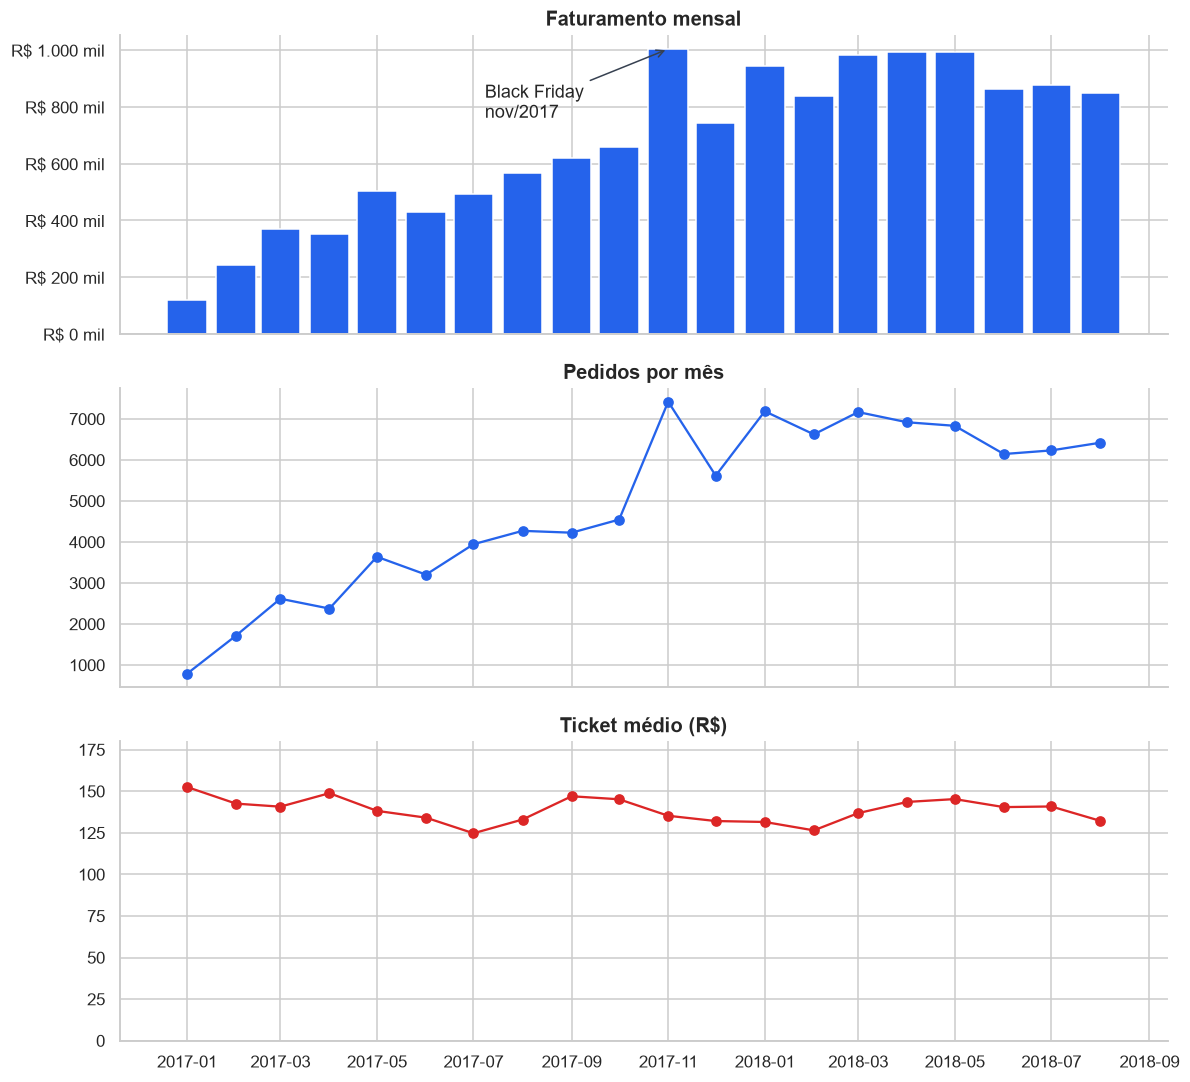

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
axes[0].bar(mensal.index, mensal["faturamento"], width=25, color=AZUL)
axes[0].set_title("Faturamento mensal"); vis.fmt_brl(axes[0])
axes[0].annotate("Black Friday\nnov/2017", (pd.Timestamp("2017-11-01"), mensal.loc["2017-11-01", "faturamento"]),
                 xytext=(-120, -45), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#374151"))
axes[1].plot(mensal.index, mensal["pedidos"], marker="o", color=AZUL); axes[1].set_title("Pedidos por mês")
axes[2].plot(mensal.index, mensal["ticket_medio"], marker="o", color=VERMELHO); axes[2].set_title("Ticket médio (R$)")
axes[2].set_ylim(0, 180)
plt.tight_layout(); vis.salvar_figura("q1_evolucao_mensal"); plt.show()

In [4]:
# Crescimento comparável: mesmos meses (jan–ago) nos dois anos
jan_ago = lambda ano: mensal.loc[f"{ano}-01":f"{ano}-08", "faturamento"].sum()
print(f"Jan–Ago 2018 vs Jan–Ago 2017: {jan_ago(2018)/jan_ago(2017)-1:+.0%}")
print(f"Abr/2018 (pico) -> Ago/2018: {mensal.loc['2018-08-01','faturamento']/mensal.loc['2018-04-01','faturamento']-1:+.1%}")

Jan–Ago 2018 vs Jan–Ago 2017: +138%
Abr/2018 (pico) -> Ago/2018: -14.6%


### 💡 Insight
- O faturamento em jan–ago/2018 foi **138% maior** que no mesmo período de 2017, e o crescimento veio de **volume de pedidos**, não de preço: o ticket ficou praticamente estável (R$ 143 no 1º trimestre de 2017 e R$ 138 em jun–ago/2018).
- **Black Friday (nov/2017):** R$ 1,00 mi e 7.421 pedidos, **+52% sobre outubro**, seguido de queda de 26% em dezembro (demanda antecipada, não nova).
- **Alerta:** o crescimento estacionou. Desde março/2018 o faturamento oscila entre R$ 850 mil e R$ 990 mil, e de abril a agosto caiu **14,6%**.

**Recomendação:** o motor atual (aquisição de pedidos) perdeu ritmo. Priorizar ações de ticket (combos, frete grátis condicionado) e de recompra (pergunta 4), e planejar a próxima Black Friday com estoque e logística reforçados.

## Pergunta 2 · Quais categorias e estados concentram mais receita?

In [5]:
# Itens válidos na janela, com categoria e estado do cliente (destino do pedido)
iv = (vis.no_periodo(fi[fi["pedido_valido"]])
      .merge(dp[["id_produto", "categoria_en"]], on="id_produto")
      .merge(fp[["id_pedido", "id_cliente"]], on="id_pedido")
      .merge(dc[["id_cliente", "uf"]], on="id_cliente"))

cat = iv.groupby("categoria_en")["receita"].sum().sort_values(ascending=False)
cat_pct = cat / cat.sum()
print(f"Top 5 categorias: {cat_pct.head(5).sum():.1%} | Top 10: {cat_pct.head(10).sum():.1%}")
print(f"Categorias necessárias para 80% da receita: {(cat_pct.cumsum() < 0.8).sum() + 1} de {len(cat)}")

Top 5 categorias: 39.9% | Top 10: 62.4%


Categorias necessárias para 80% da receita: 18 de 74


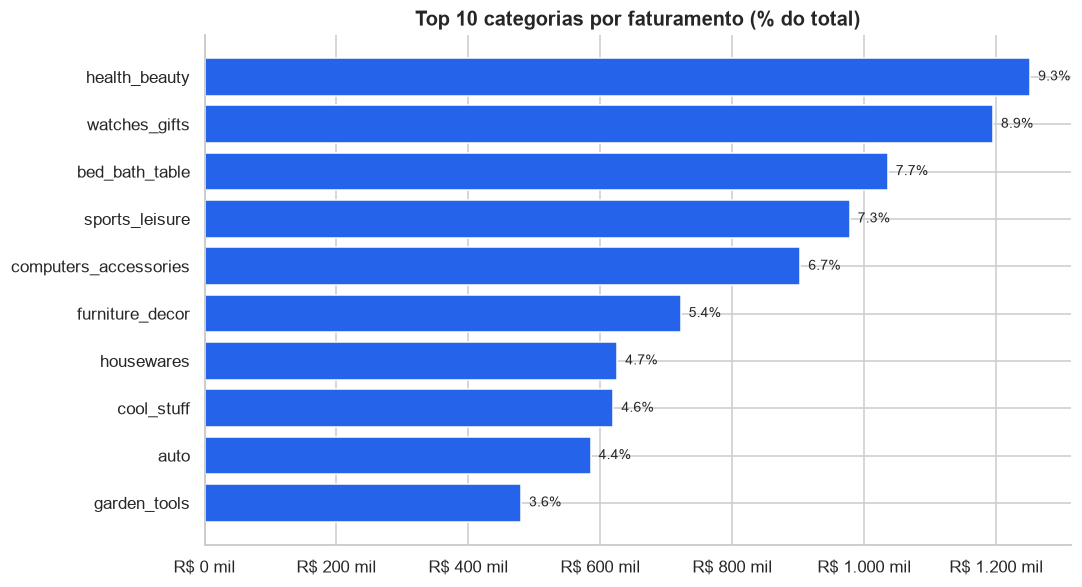

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
top = cat.head(10)[::-1]
ax.barh(top.index, top.values, color=AZUL)
for y, v in enumerate(top.values):
    ax.text(v, y, f"  {v/cat.sum():.1%}", va="center", fontsize=9)
ax.set_title("Top 10 categorias por faturamento (% do total)"); vis.fmt_brl(ax, "x")
plt.tight_layout(); vis.salvar_figura("q2_top_categorias"); plt.show()

SP: 38.3% | SP+RJ+MG: 63.4%


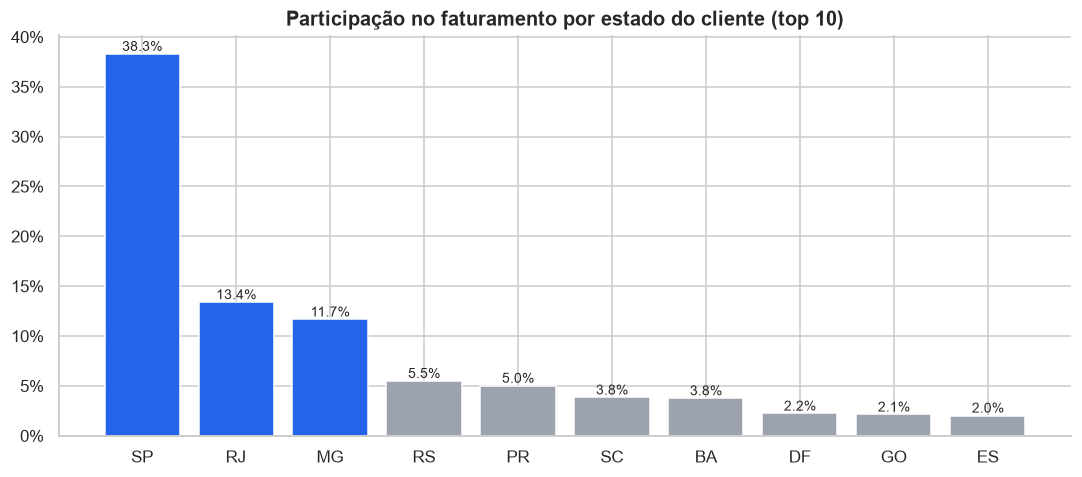

,rev,pedidos,ticket
uf,,,
PB,114824.0,530,217.0
AL,80232.0,409,196.0
PA,177734.0,965,184.0
PI,86450.0,489,177.0
MT,155986.0,900,173.0


In [7]:
uf = iv.groupby("uf")["receita"].sum().sort_values(ascending=False)
uf_pct = uf / uf.sum()
print(f"SP: {uf_pct['SP']:.1%} | SP+RJ+MG: {uf_pct[['SP','RJ','MG']].sum():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.5))
t = uf_pct.head(10)
ax.bar(t.index, t.values, color=[AZUL if i < 3 else CINZA for i in range(len(t))])
for i, v in enumerate(t.values):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_title("Participação no faturamento por estado do cliente (top 10)"); vis.fmt_pct(ax)
plt.tight_layout(); vis.salvar_figura("q2_top_estados"); plt.show()

# Ticket por pedido por estado (apenas estados com >= 300 pedidos)
tk = iv.groupby("uf").agg(rev=("receita", "sum"), pedidos=("id_pedido", "nunique"))
tk["ticket"] = tk.rev / tk.pedidos
tk[tk.pedidos >= 300].sort_values("ticket", ascending=False).head(5).round(0)

### 💡 Insight
- **Categorias:** as 5 maiores (saúde e beleza, relógios e presentes, cama/mesa/banho, esporte e lazer, informática) somam **39,9%** da receita, e as 10 maiores **62,4%**. Só **18 das 74 categorias** geram 80% do faturamento.
- **Geografia:** **SP concentra 38,3%** e SP+RJ+MG **63,4%**. O Sudeste é o mercado, e o resto do país é cauda.
- Estados do Nordeste e Norte têm ticket maior (ex.: PB com R$ 217 por pedido vs R$ 137 da média), mas em volume pequeno.

**Recomendação:** concentrar sortimento e investimento de marketing nas ~18 categorias que sustentam a receita. Tratar Nordeste/Norte como oportunidade de ticket alto, **desde que a logística entregue** (veja a pergunta 5).

## Pergunta 3 · Qual o impacto do atraso na nota de avaliação?

In [8]:
# Pedidos entregues (com data) e avaliados. dias_atraso > 0 = atrasou
e = fp[fp["atrasado"].notna() & fp["nota_avaliacao"].notna()].copy()
e["faixa"] = pd.cut(e["dias_atraso"], [-1e9, -1, 0, 3, 7, 14, 1e9],
                    labels=["Adiantado", "No dia", "1–3 dias", "4–7 dias", "8–14 dias", "> 14 dias"])

por_faixa = e.groupby("faixa", observed=True).agg(pedidos=("id_pedido", "count"), nota_media=("nota_avaliacao", "mean"),
                                                  pct_nota_1_2=("nota_avaliacao", lambda s: (s <= 2).mean()))
resumo = e.groupby("atrasado").agg(pedidos=("id_pedido", "count"), nota_media=("nota_avaliacao", "mean"),
                                  pct_nota_1_2=("nota_avaliacao", lambda s: (s <= 2).mean()),
                                  pct_nota_5=("nota_avaliacao", lambda s: (s == 5).mean()))
print(resumo.round(3).to_string()); print()
print(f"Correlação nota x dias de atraso: {e[['dias_atraso','nota_avaliacao']].corr().iloc[0,1]:.2f} | "
      f"nota x tempo total de entrega: {e[['dias_entrega','nota_avaliacao']].corr().iloc[0,1]:.2f}")
por_faixa.round(3)

          pedidos  nota_media  pct_nota_1_2  pct_nota_5
atrasado                                               
False       89443        4.29         0.093       0.623
True         6381        2.27         0.624       0.165

Correlação nota x dias de atraso: -0.27 | nota x tempo total de entrega: -0.33


,pedidos,nota_media,pct_nota_1_2
faixa,,,
Adiantado,88163,4.294,0.092
No dia,1280,4.034,0.124
1–3 dias,1852,3.291,0.321
4–7 dias,1748,2.103,0.677
8–14 dias,1446,1.671,0.802
> 14 dias,1335,1.724,0.784


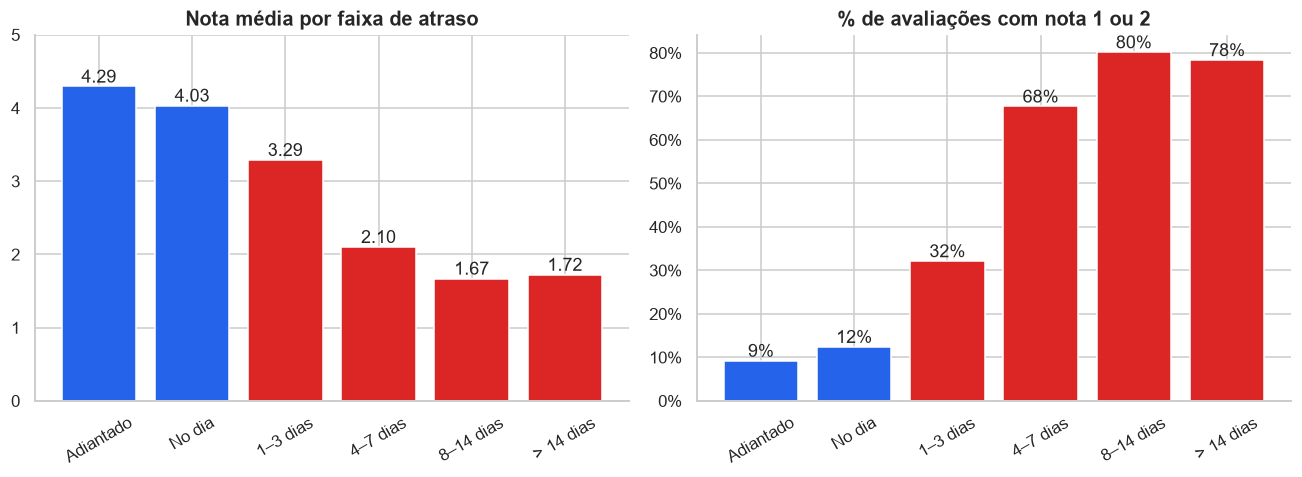

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cores = [AZUL, AZUL, VERMELHO, VERMELHO, VERMELHO, VERMELHO]
axes[0].bar(por_faixa.index.astype(str), por_faixa["nota_media"], color=cores)
for i, v in enumerate(por_faixa["nota_media"]):
    axes[0].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axes[0].set_title("Nota média por faixa de atraso"); axes[0].set_ylim(0, 5)
axes[1].bar(por_faixa.index.astype(str), por_faixa["pct_nota_1_2"], color=cores)
for i, v in enumerate(por_faixa["pct_nota_1_2"]):
    axes[1].text(i, v, f"{v:.0%}", ha="center", va="bottom")
axes[1].set_title("% de avaliações com nota 1 ou 2"); vis.fmt_pct(axes[1])
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); vis.salvar_figura("q3_atraso_vs_nota"); plt.show()

### 💡 Insight
- Pedido atrasado recebe nota média **2,27 vs 4,29** do pedido no prazo. **62% dos atrasados dão nota 1 ou 2**, contra 9% dos que chegam no prazo.
- A queda é **rápida**: com apenas 1–3 dias de atraso a nota já cai para 3,29, e a partir de 4 dias ela fica entre 1,7 e 2,1 (**68% a 80% de notas 1–2**). Depois de uma semana de atraso a nota praticamente não piora mais.
- Chegar adiantado (4,29) é melhor do que chegar no dia (4,03). A correlação com o **tempo total de entrega** (-0,33) é mais forte que com o atraso (-0,27), então esperar muito incomoda mesmo quando a promessa é cumprida.

**Recomendação:** a meta operacional deve ser **zero atrasos acima de 3 dias**, onde está a maior perda de satisfação. Como a promessa pesa tanto quanto o prazo em si, trabalhar com **estimativas mais conservadoras** nas regiões lentas é uma alavanca barata: ganha-se nota sem mudar a operação.